# Mumbai Local Train Crowding Analyzer
**SIMULATED — estimated crowding patterns only.**
Reproducible source, recorded execution outputs and charts. Run with this notebook in the project directory. Detailed steps 1–9 are in README.md.

In [1]:
"""SIMULATED Mumbai suburban crowding portfolio. Run: python analysis.py"""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path.cwd()
OUT = ROOT / 'outputs'; OUT.mkdir(exist_ok=True)
CHARTS = ROOT / 'charts'; CHARTS.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
stations = {'Western':['Borivali','Andheri','Dadar'],
            'Central':['Thane','Ghatkopar','Dadar'],
            'Harbour':['Vashi','Chembur','Wadala Road']}
rows = []
# Entire timetable, station selection, demand and service intervals are invented.
for date in ['2026-11-09','2026-11-14']:
    day = 'weekday' if pd.Timestamp(date).dayofweek < 5 else 'weekend'
    for line, stops in stations.items():
        for direction in ['towards_terminus','away_from_terminus']:
            order = stops if direction == 'towards_terminus' else stops[::-1]
            types = ['slow'] if line == 'Harbour' else ['slow','fast']
            for typ in types:
                interval = 10 if typ == 'slow' else 20
                for start in range(300, 1410, interval):
                    service = f'{date}_{line}_{direction}_{typ}_{start}'
                    for pos, station in enumerate(order):
                        minute = start + pos * (9 if typ == 'slow' else 6)
                        hour = minute / 60
                        morning = np.exp(-0.5*((hour-9.3)/1.15)**2)
                        evening = np.exp(-0.5*((hour-18.8)/1.5)**2)
                        directional = (65*morning+20*evening if direction == 'towards_terminus'
                                       else 18*morning+68*evening)
                        load = (29 + directional*(1 if day=='weekday' else .48)
                                + {'Western':4,'Central':9,'Harbour':-5}[line]
                                + (5 if typ=='fast' else 0) + pos*2
                                + rng.normal(0,7))
                        rows.append([service,line,station,direction,
                                     pd.Timestamp(date)+pd.Timedelta(minutes=minute),typ,day,
                                     round(float(np.clip(load,5,145)),2)])
cols = ['service_id','line','station','direction','departure_time','train_type','day_type','estimated_passenger_load']
pristine = pd.DataFrame(rows,columns=cols)
raw = pristine.copy()
# Deliberate, reproducible quality defects; never silently replace missing loads with truth.
ix = rng.choice(raw.index,90,replace=False)
raw.loc[ix[:30],'estimated_passenger_load'] = np.nan
raw.loc[ix[30:60],'station'] = raw.loc[ix[30:60],'station'].str.upper().map(lambda s:' '+s+' ')
raw.loc[ix[60:],'train_type'] = raw.loc[ix[60:],'train_type'].str.upper()
raw = pd.concat([raw,raw.iloc[:25]],ignore_index=True)
raw.to_csv(ROOT/'simulated_raw.csv',index=False)
print('1. DATA SETUP: SIMULATED rows:',len(raw))
print('Dates: one weekday and one weekend; not an actual operating timetable.')
print('\n2. CLEANING\nMissing before:\n',raw.isna().sum().to_string())
print('Exact duplicates:',raw.duplicated().sum())
df = raw.drop_duplicates().copy()
canonical = {s.upper():s for stops in stations.values() for s in stops}
station_fixes = (df.station != df.station.str.strip().str.upper().map(canonical)).sum()
df['station'] = df.station.str.strip().str.upper().map(canonical)
type_fixes = (df.train_type != df.train_type.str.lower()).sum()
df['train_type'] = df.train_type.str.lower()
df['departure_time'] = pd.to_datetime(df.departure_time,errors='coerce')
df['estimated_passenger_load'] = pd.to_numeric(df.estimated_passenger_load,errors='coerce')
df['load_imputed'] = df.estimated_passenger_load.isna()
df['hour'] = df.departure_time.dt.hour
groups = ['line','station','direction','day_type','train_type','hour']
med = df.groupby(groups).estimated_passenger_load.transform('median')
df['estimated_passenger_load'] = df.estimated_passenger_load.fillna(med)
assert df[cols].notna().all().all()
assert df.estimated_passenger_load.between(0,150).all()
assert not df.duplicated(['service_id','station']).any()
df['time_band'] = pd.cut(df.hour,bins=[-1,7,10,16,20,23],
    labels=['early morning','morning peak','midday','evening peak','night']).astype(str)
df['is_peak'] = df.hour.between(8,10) | df.hour.between(17,20)
print(f'Fixed {station_fixes} station labels, {type_fixes} train-type labels; imputed {df.load_imputed.sum()} loads with same-segment hourly medians.')
print('Converted timestamps and numeric loads; added hour, time_band, is_peak. Remaining nulls:',df.isna().sum().sum())

# Frequency is the previous departure gap for the same station, direction and type,
# separately for each service date; no overnight gaps or cross-direction mixing.
df['service_date'] = df.departure_time.dt.strftime('%Y-%m-%d')
keys = ['service_date','line','station','direction','train_type']
df = df.sort_values(keys+['departure_time'])
df['gap_minutes'] = df.groupby(keys).departure_time.diff().dt.total_seconds()/60
df['gap_imputed'] = df.gap_minutes.isna()
df['gap_minutes'] = df.gap_minutes.fillna(df.groupby(keys).gap_minutes.transform('median'))
load_score = (df.estimated_passenger_load/120*100).clip(0,100)
gap_score = (df.gap_minutes/20*100).clip(0,100)
df['crowding_index'] = (0.8*load_score+0.2*gap_score).round(2)
df['crowding_category'] = pd.cut(df.crowding_index,[-.001,25,50,75,100],
    labels=['Low','Moderate','High','Very High']).astype(str)
df.to_csv(ROOT/'simulated_clean.csv',index=False)
summary = {}
print('\n3. ESTIMATED CROWDING PATTERNS')
for col in ['hour','line','day_type','train_type']:
    table = df.groupby(col).agg(mean_estimated_load=('estimated_passenger_load','mean'),
                              mean_index=('crowding_index','mean'),departures=('service_id','size')).round(2)
    summary[col] = table
    table.to_csv(OUT/f'average_by_{col}.csv')
    print('\nBy',col,'\n',table.to_string())
combo_cols = ['line','station','direction','day_type','hour','train_type']
combo = df.groupby(combo_cols).agg(mean_estimated_load=('estimated_passenger_load','mean'),
    departures=('service_id','size')).reset_index()
most = combo.nlargest(10,'mean_estimated_load'); least = combo.nsmallest(10,'mean_estimated_load')
most.to_csv(OUT/'top10_highest.csv',index=False); least.to_csv(OUT/'top10_lowest.csv',index=False)
print('\nTop 10 highest station-hour segments:\n',most.to_string(index=False))
print('\nTop 10 lowest station-hour segments:\n',least.to_string(index=False))
plt.style.use('seaborn-v0_8-whitegrid')
fig,axes = plt.subplots(2,2,figsize=(13,8))
for ax,col in zip(axes.flat,['hour','line','day_type','train_type']):
    s = summary[col].mean_estimated_load
    if col=='hour': ax.plot(s.index,s.values,marker='o',color='#007f86')
    else: ax.bar(s.index,s.values,color=['#007f86','#de9151','#5968a5'][:len(s)])
    ax.set(title=f'Mean estimated load by {col.replace("_"," ")}',ylabel='Estimated load (% capacity)',xlabel=col.replace('_',' ').title())
fig.suptitle('SIMULATED — estimated crowding patterns',fontsize=16)
fig.tight_layout(); fig.savefig(CHARTS/'overview.png',dpi=160); plt.close(fig)
heat = df.pivot_table(index='line',columns='hour',values='crowding_index',aggfunc='mean')
fig,ax=plt.subplots(figsize=(13,3.6))
im=ax.imshow(heat.values,aspect='auto',cmap='YlOrRd',vmin=0,vmax=100)
ax.set_xticks(range(len(heat.columns)),heat.columns); ax.set_yticks(range(len(heat.index)),heat.index)
ax.set(xlabel='Departure hour',ylabel='Line',title='SIMULATED — mean estimated Crowding Index (0–100)')
fig.colorbar(im,ax=ax,label='Crowding Index'); fig.tight_layout(); fig.savefig(CHARTS/'heatmap.png',dpi=160); plt.close(fig)
labels = lambda t: t.apply(lambda r:f'{r.station} | {r.direction.replace("_from_"," ← ").replace("_"," ")} | {r.day_type} {r.hour:02d}:00 | {r.train_type}',axis=1)
fig,axes=plt.subplots(1,2,figsize=(17,7))
for ax,t,title,color in [(axes[0],most,'Highest','#b65341'),(axes[1],least,'Lowest','#007f86')]:
    ax.barh(range(len(t)),t.mean_estimated_load,color=color); ax.set_yticks(range(len(t)),labels(t),fontsize=8)
    ax.invert_yaxis(); ax.set(xlabel='Mean estimated load (% capacity)',title=f'{title} 10 station-hour segments')
fig.suptitle('SIMULATED — estimated crowding patterns'); fig.tight_layout(); fig.savefig(CHARTS/'station_segments.png',dpi=160); plt.close(fig)

def best_departures(station,direction,preferred_time,line=None):
    """Up to three scheduled stops within inclusive ±30 min; full date required."""
    station = canonical.get(str(station).strip().upper())
    if station is None: raise ValueError('Unknown station')
    if direction not in ['towards_terminus','away_from_terminus']: raise ValueError('Invalid direction')
    t=pd.Timestamp(preferred_time)
    candidates=df[(df.station==station)&(df.direction==direction)&
        (df.departure_time.between(t-pd.Timedelta(minutes=30),t+pd.Timedelta(minutes=30)))].copy()
    if line is not None: candidates=candidates[candidates.line==line]
    candidates['minutes_from_preference']=(candidates.departure_time-t).dt.total_seconds().abs()/60
    return candidates.sort_values(['crowding_index','estimated_passenger_load','minutes_from_preference','departure_time','service_id']).head(3)[
        ['line','station','direction','departure_time','train_type','estimated_passenger_load','gap_minutes','crowding_index','crowding_category']]

recommendations=best_departures('Andheri','towards_terminus','2026-11-09 09:00',line='Western')
recommendations.to_csv(OUT/'example_best_departures.csv',index=False)
print('\n4. INDEX: 80% normalized load + 20% normalized service gap.\n',df.crowding_category.value_counts().to_string())
print('\n5. BEST DEPARTURES, Andheri towards terminus, 9 Nov 09:00 ±30 minutes:\n',recommendations.to_string(index=False))
metrics={'rows_raw':len(raw),'rows_clean':len(df),'avg_index':round(df.crowding_index.mean(),2),
         'busiest_hour':int(summary['hour'].mean_estimated_load.idxmax()),
         'least_crowded_line':summary['line'].mean_index.idxmin(),
         'weekday_load':float(summary['day_type'].loc['weekday','mean_estimated_load']),
         'weekend_load':float(summary['day_type'].loc['weekend','mean_estimated_load']),
         'peak_load':round(df.loc[df.is_peak,'estimated_passenger_load'].mean(),2),
         'nonpeak_load':round(df.loc[~df.is_peak,'estimated_passenger_load'].mean(),2)}
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2))
with pd.ExcelWriter(ROOT/'crowding_analysis.xlsx',engine='openpyxl') as writer:
    df.to_excel(writer,sheet_name='Simulated data',index=False)
    for col,table in summary.items(): table.to_excel(writer,sheet_name=f'By {col}')
    most.to_excel(writer,sheet_name='Highest 10',index=False)
    least.to_excel(writer,sheet_name='Lowest 10',index=False)
    recommendations.to_excel(writer,sheet_name='Example departures',index=False)
    pd.DataFrame([metrics]).to_excel(writer,sheet_name='KPIs',index=False)
    from openpyxl.styles import Font,PatternFill
    from openpyxl.chart import BarChart,Reference
    for ws in writer.book.worksheets:
        ws.freeze_panes='A2'; ws.auto_filter.ref=ws.dimensions
        for cell in ws[1]: cell.font=Font(color='FFFFFF',bold=True); cell.fill=PatternFill('solid',fgColor='007F86')
        for column in ws.columns:
            letter=column[0].column_letter
            ws.column_dimensions[letter].width=min(32,max(14,max(len(str(c.value)) for c in list(column)[:100])+2))
    ws=writer.book['By hour']; chart=BarChart(); chart.title='SIMULATED hourly estimated load'
    chart.y_axis.title='Estimated load (% capacity)'; chart.x_axis.title='Hour'
    chart.add_data(Reference(ws,min_col=2,max_col=2,min_row=1,max_row=ws.max_row),titles_from_data=True)
    chart.set_categories(Reference(ws,min_col=1,min_row=2,max_row=ws.max_row)); ws.add_chart(chart,'F2')
print('\nMETRICS\n',json.dumps(metrics,indent=2))


1. DATA SETUP: SIMULATED rows: 5365
Dates: one weekday and one weekend; not an actual operating timetable.

2. CLEANING
Missing before:
 service_id                   0
line                         0
station                      0
direction                    0
departure_time               0
train_type                   0
day_type                     0
estimated_passenger_load    30
Exact duplicates: 25
Fixed 30 station labels, 30 train-type labels; imputed 30 loads with same-segment hourly medians.
Converted timestamps and numeric loads; added hour, time_band, is_peak. Remaining nulls: 0

3. ESTIMATED CROWDING PATTERNS

By hour 
       mean_estimated_load  mean_index  departures
hour                                             
5                   35.99       36.60         276
6                   37.52       37.52         288
7                   45.49       42.83         288
8                   59.13       51.92         288
9                   64.69       55.62         288
10          

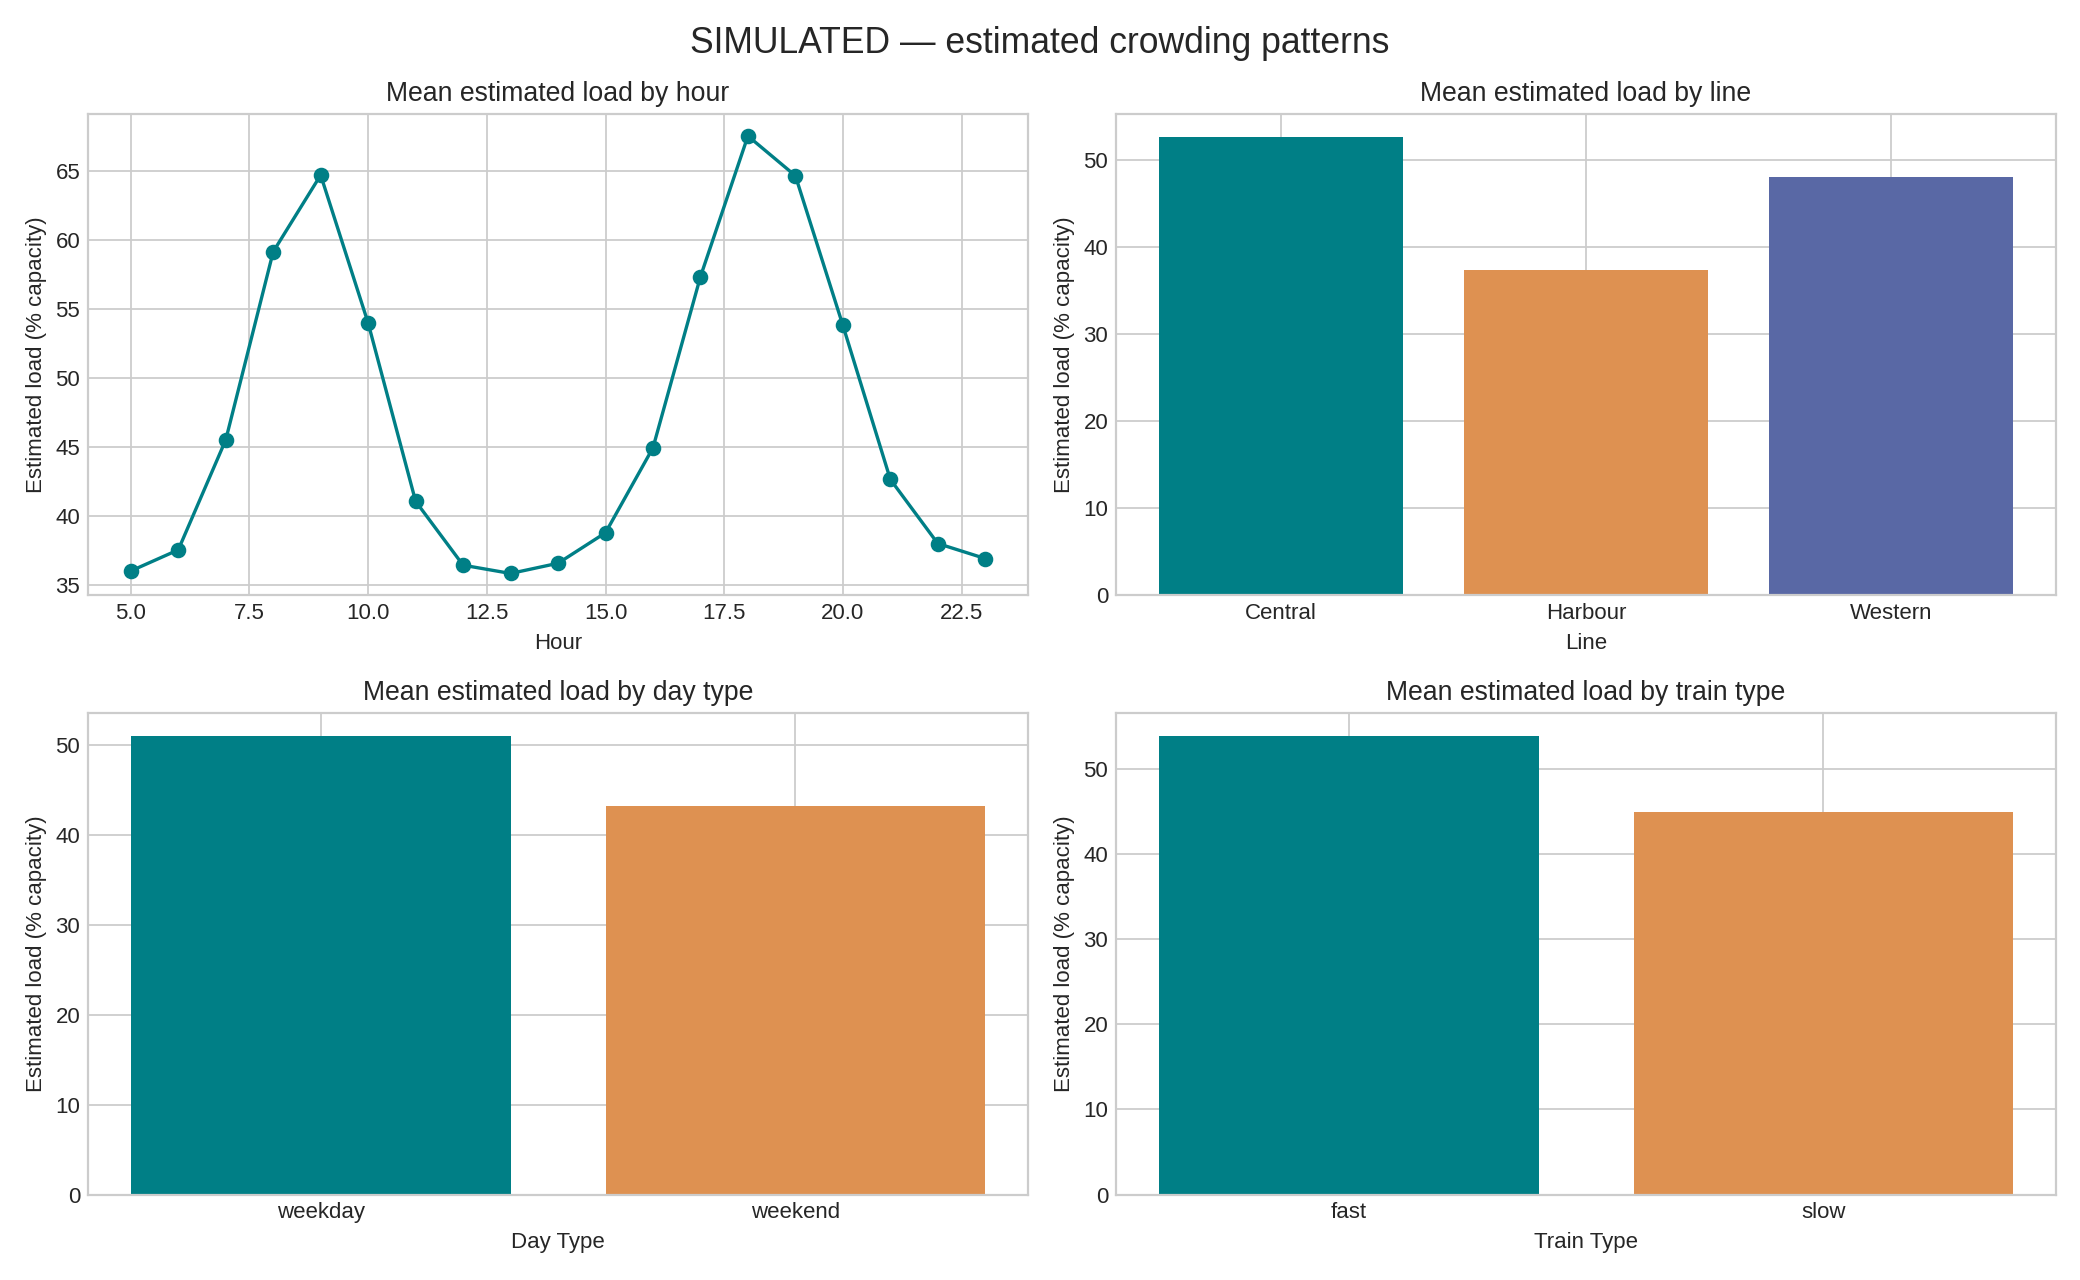

In [2]:
from IPython.display import Image, display
display(Image(filename=str(CHARTS / 'overview.png')))

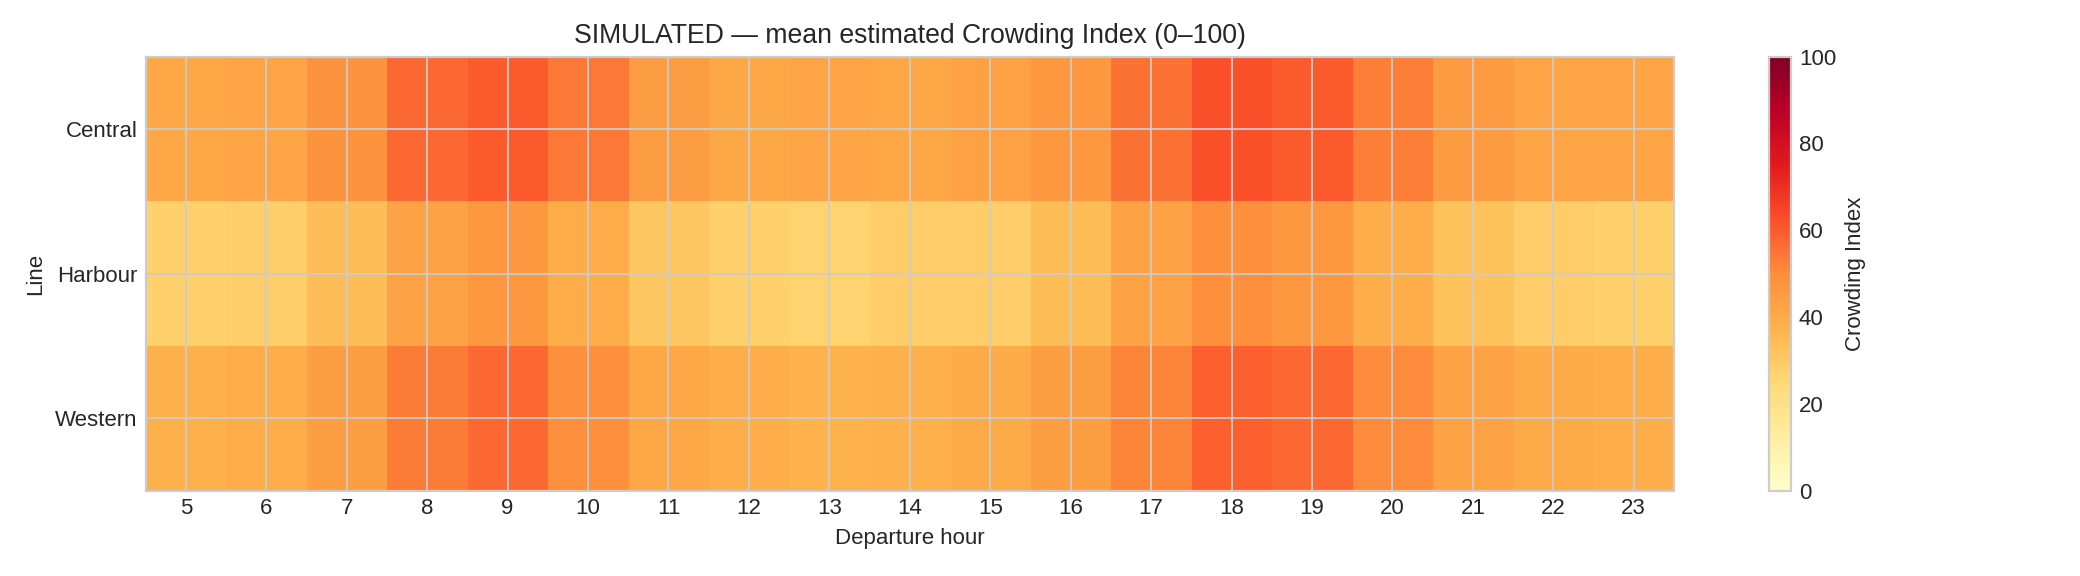

In [3]:
from IPython.display import Image, display
display(Image(filename=str(CHARTS / 'heatmap.png')))

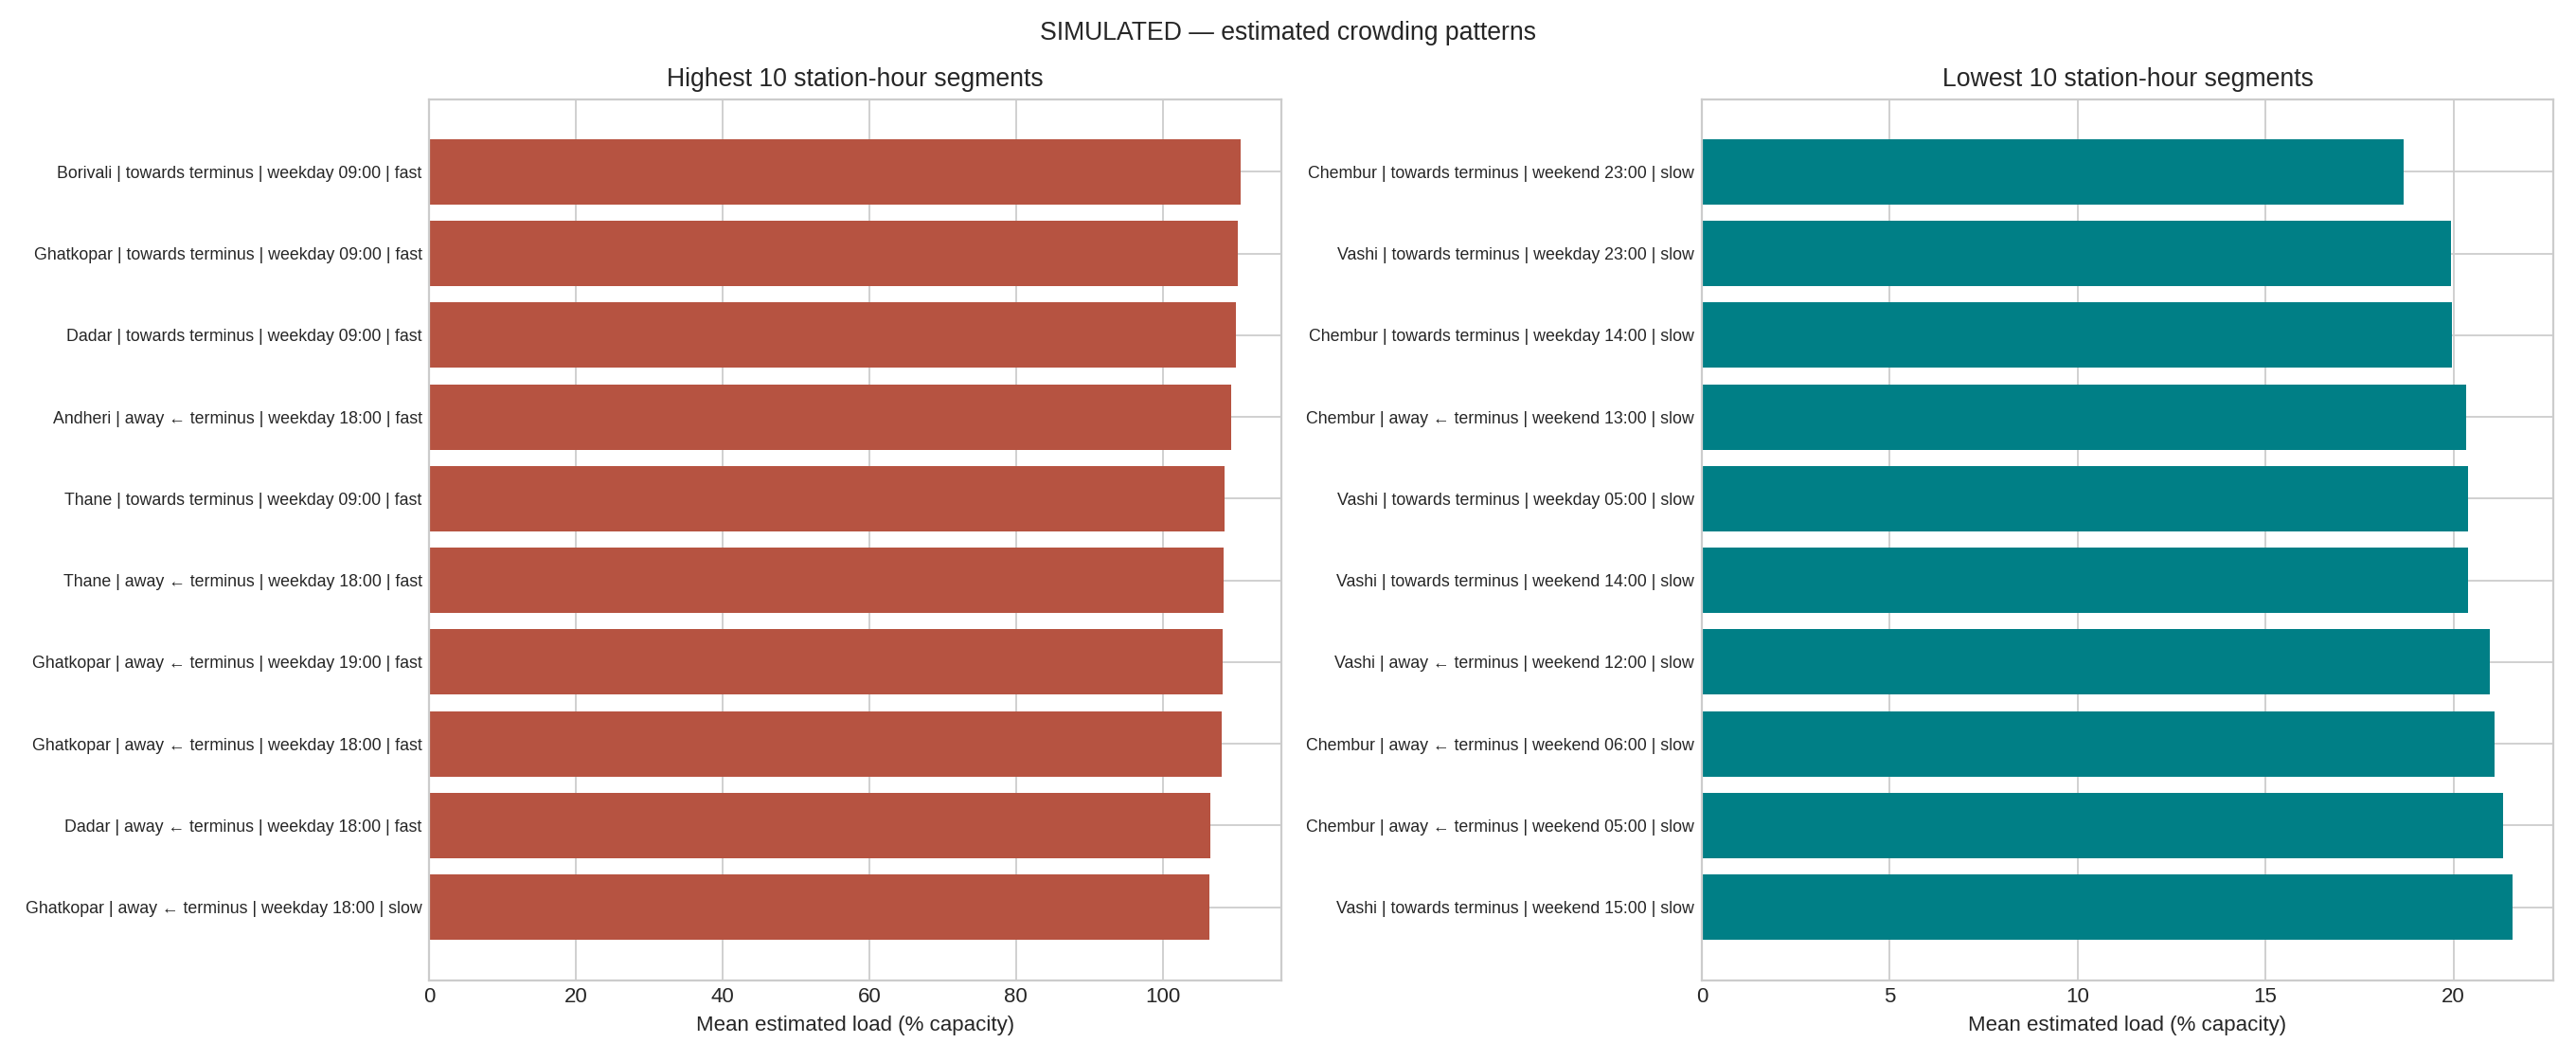

In [4]:
from IPython.display import Image, display
display(Image(filename=str(CHARTS / 'station_segments.png')))

# Mumbai Local Train Crowding Analyzer
**Python · pandas · SQL (MySQL 8+) · Excel · Power BI**

> SIMULATED DATA ONLY. All results are estimated crowding patterns, not verified passenger counts, actual schedules or real-world travel advice.

## Problem statement
Demonstrate how a data analyst can compare directional time-of-day demand, summarize station-departure observations, and rank alternative departure windows. Timetables alone cannot establish passenger occupancy.

## Dataset and assumptions
- 5,365 raw rows → 5,340 cleaned station-departure observations; seed 42.
- Invented service dates: Monday, November 9, 2026 and Saturday, November 14, 2026; these are scenario dates, not observations.
- Western: Borivali, Andheri, Dadar; Central: Thane, Ghatkopar, Dadar; Harbour: Vashi, Chembur, Wadala Road. These are a small illustrative subset, not full line coverage.
- `towards_terminus`: Churchgate for Western and CSMT (formerly CST) for Central/Harbour; reverse is `away_from_terminus`.
- Toy service grid: slow every 10 minutes; fast every 20 minutes on Western/Central; Harbour slow only. Station offsets 9/6 minutes. This is not a reconstruction of real services, stop patterns, running times or frequencies.
- One row = one train stop at one station. A train appears at multiple stops; rows are correlated. Means weight station departures equally, not passengers or unique trains.
- Load is expressed in percentage points of an assumed capacity. 100 means nominal capacity; >100 allows overcapacity. No capacity denominator is measured, and no absolute passenger counts can be recovered.
- Demand uses smooth synthetic peaks centered at 09:18 and 18:48, stronger inbound in the morning and outbound in the evening; weekday/weekend, line, train-type and random effects are explicitly imposed. These are modeling assumptions, not independently discovered behavior.

### Columns
Required: line, station, direction, departure_time, train_type, day_type, estimated_passenger_load.
Extra: service_id (train run), load_imputed, hour, time_band, is_peak, service_date, gap_minutes, gap_imputed, crowding_index, crowding_category.

## Reproduce
```bash
pip install -r requirements.txt
python analysis.py
```
Open `analysis.ipynb` for source, saved execution outputs and charts. The script regenerates the CSVs, chart PNGs, Excel workbook and aggregate outputs. Notebook exports reflect the supplied run.

## 1–2. Setup and cleaning
Raw data intentionally contains 25 duplicate records, 30 missing loads, 30 whitespace/case station inconsistencies and 30 uppercase train-type labels. CSV timestamp strings become datetime; loads become numeric. Remove exact duplicates, canonicalize station names, lowercase train types, and impute missing loads with the median for the same line/station/direction/day type/train type/hour. Mark imputed rows. Assertions test missingness, load range and stop uniqueness.

Time bands: early morning 00:00–07:59 (generated data begins 05:00), morning peak 08:00–10:59, midday 11:00–16:59, evening peak 17:00–20:59, night 21:00–23:59. `is_peak` is clock-based, including weekends and both directions; it is not evidence that every such departure is crowded.

## 3. Exploratory analysis
See outputs/average_by_*.csv and charts/overview.png for means by hour, line, day type and train type. Highest and lowest 10 segments are in outputs/top10_highest.csv and outputs/top10_lowest.csv, with line, station, direction, day type, hour and train type preserved to avoid mixing distinct travel contexts. Every segment contains multiple departures. charts/station_segments.png plots both lists; charts/heatmap.png summarizes hourly index by line.

## 4. Crowding Index
```
load_score = min(100, max(0, estimated_load / 120 * 100))
gap_score  = min(100, max(0, previous_gap_minutes / 20 * 100))
index      = 0.80 * load_score + 0.20 * gap_score
```
Interview explanation: “I normalize estimated occupancy and waiting gaps onto the same 0–100 scale, then give occupancy 80% of the weight and the service gap 20%. Higher means a less desirable departure under these assumptions.”

Index categories: Low [0,25], Moderate (25,50], High (50,75], Very High (75,100]. These cutoffs, 120%-capacity saturation, 20-minute gap saturation and weights are hand-selected and uncalibrated, not industry standards. Loads above 120% saturate the index's load component.

Gaps are computed between consecutive scheduled departures within date/line/station/direction/train type, not across dates or opposite directions. The first gap in each group uses that group's median gap (60 imputed gaps). Fast and slow frequencies are deliberately separate, so this models waiting for the same train type rather than any usable train; overlapping slow/fast alternatives would change the result. Gaps are regular by design and add little temporal variation within a service type. Avoid claims of independent frequency-driven crowding validation or double counting occupancy and waiting.

## 5. Departure-window function
```python
best_departures('Andheri', 'towards_terminus', '2026-11-09 09:00', line='Western')
```
Returns up to three lowest-index scheduled departures within inclusive ±30 minutes, ordered by index, estimated load, closeness to preference, time and service ID. Full date required. No matches returns an empty table. Optional line disambiguates Dadar; omitting it deliberately considers both lines there. There is no destination/stop compatibility check, realtime information or delay forecast.

Example output (all slow, Western, towards terminus):
| Departure | Estimated load (% capacity) | Index | Category |
|---|---:|---:|---|
| 08:59 | 88.65 | 69.10 | High |
| 08:49 | 91.27 | 70.85 | High |
| 08:39 | 95.38 | 73.59 | High |

Least crowded among eligible alternatives does not necessarily mean low crowding. At deployment, only future departures relative to an actual current timestamp should be offered; this is retrospective simulation lookup.

## 6. SQL
queries.sql includes table DDL and six queries: line means, peak vs non-peak, top-five station ranks per line, hourly trends, lowest-index departures using a CTE, and ±30-minute recommendations. The request lists five query topics but asks for six; the sixth implements the recommendation search. The sample has three stations per line, so the top-five query can return only three. RANK retains ties and can return more than five on larger tied datasets. MySQL 8+ required for CTEs/window functions. SQL is authored, not executed against a MySQL server here. Convert CSV True/False strings to 1/0 in the import wizard before loading BOOLEAN fields; column order matches the cleaned CSV.

## 7. Excel and Power BI
crowding_analysis.xlsx contains the clean data, grouped summaries, a native Excel hourly chart, highest/lowest segments, example departures and KPI sheet. POWER_BI.md provides the complete report layout, DAX measures and manual build/validation steps. No PBIX file is included and no Power BI execution is claimed.

## 8. Findings: estimated crowding patterns
1. Central has the highest mean estimated load (52.68%), followed by Western (48.09%) and Harbour (37.41%); imposed line effects and differing service mix partly explain this ranking.
2. Weekday mean load is 51.02% vs 43.28% on weekends, a 7.74-percentage-point difference imposed by the simulation's weekday multiplier.
3. Peak clock bands average 60.15% versus 39.26% outside those bands: a 20.89-point difference. 18:00–18:59 is the highest-load hour overall.
4. Morning inbound mean load is 73.03%, while evening outbound mean load is 74.31%, reproducing the directional assumptions built into the generator.
5. Fast services average 53.81% compared with 44.91% for slow services; this is not a causal fast-train effect because Harbour has no fast-service records and a lower baseline. Overall mean index is 43.95; Harbour has the lowest line mean index (34.94).

### Three commuter-oriented recommendations (illustrative, simulation only)
- Explore off-peak alternatives when flexible, but compare the same line, direction and day type rather than assuming every off-peak train is empty.
- Rank nearby departures inside a personal time window; the Andheri 09:00 example still returns High-category choices, so state absolute crowding as well as relative rank.
- Check train stopping pattern, destination, actual timetable and live conditions before travel; this prototype cannot support real-world departure decisions.

## Limitations and next steps
Only two invented dates, nine line-station pairs (eight distinct station names), fixed headways, no holidays, disruptions, events, weather, destinations or passenger observations. Station effects are simplified and train capacity varies in reality. No inference, statistical significance, forecast accuracy, calibrated occupancy, measured commute benefit, or historical trend claims are supported. Validate against ethically collected occupancy/boarding data and real timetable snapshots before practical use. Test index weights and cutoffs, distinguish joint-service frequency from type-specific frequency, add multiple dates and evaluate on a held-out observed dataset. The generated findings mainly confirm generator assumptions.

## 9. Resume bullets (use only after reproducing and understanding the work)
- Built a reproducible Python/pandas pipeline for 5,340 simulated Mumbai suburban station-departure observations across 3 lines, removing 25 duplicates and flagging/imputing 30 missing load values.
- Designed a transparent 0–100 Crowding Index combining estimated occupancy and service gaps, and implemented a function ranking up to 3 departures within a ±30-minute preference window.
- Produced 6 MySQL 8 analytical queries, an Excel analysis workbook and a Power BI dashboard specification; quantified a simulated 20.89-percentage-point peak/off-peak estimated-load difference.

### Five interview questions and short answers
1. **Can timetables tell you actual crowding?** No. They describe supply, not occupancy. I used explicitly simulated loads and made no observed passenger-count claims.
2. **Why use an 80/20 index?** Occupancy is the primary signal and gaps are a secondary waiting-time proxy. Weights and thresholds are illustrative and require sensitivity checks and real-data validation.
3. **How did you clean missing or inconsistent records?** Removed 25 exact duplicates, standardized 30 station labels and 30 train-type labels, converted types and median-imputed 30 same-segment hourly loads with an audit flag.
4. **What is the analysis grain?** A train stop at a station. The same service appears multiple times, so rows are correlated; mean load is station-departure-weighted, not unique-train or passenger-weighted.
5. **How would you productionize it?** Acquire validated timetable and occupancy feeds, implement data-quality and destination-compatibility checks, calibrate the index, validate on held-out observed dates and monitor drift and delays.
